# Step 1 — Import libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Step 2 — Load the ATM CSV dataset

In [3]:
df = pd.read_csv(Path("..") / "Dataset" / "ATM_Cash_Demand.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 6000
Number of columns: 22


In [4]:
display(df.head())

,ATM_ID,Date,Day_of_week,Location,City,Day,Month,Year,ATM_Capacity,Total_Current_Cash,Total_Withdraw_Cash,Total_deposite_Cash,No_of_Deposits,No_of_Withdraws,Temperature,Weather_Condition,Holiday_Flag,Festival_Flag,Previous_Day_Cash_Level,Cash_Demand_Next_Day,Replenishment_Required,Replenishment_Amount
0,ATM001,2024-01-01,Monday,Mall,Mumbai,1,1,2024,3000000,2430300,713500,143800,21,217,12.3,Cloudy,0,0,3000000,707800,0,0
1,ATM001,2024-01-02,Tuesday,Mall,Mumbai,2,1,2024,3000000,1855700,707800,133200,19,210,13.5,Sunny,0,0,2430300,638000,0,0
2,ATM001,2024-01-03,Wednesday,Mall,Mumbai,3,1,2024,3000000,1291700,638000,74000,12,193,12.2,Sunny,0,0,1855700,587200,0,0
3,ATM001,2024-01-04,Thursday,Mall,Mumbai,4,1,2024,3000000,804000,587200,99500,13,145,9.3,Sunny,0,0,1291700,678000,0,0
4,ATM001,2024-01-05,Friday,Mall,Mumbai,5,1,2024,3000000,281100,678000,155100,22,171,15.8,Foggy,0,0,804000,582600,1,2720000


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 6000
Number of columns: 22

Column names:
['ATM_ID', 'Date', 'Day_of_week', 'Location', 'City', 'Day', 'Month', 'Year', 'ATM_Capacity', 'Total_Current_Cash', 'Total_Withdraw_Cash', 'Total_deposite_Cash', 'No_of_Deposits', 'No_of_Withdraws', 'Temperature', 'Weather_Condition', 'Holiday_Flag', 'Festival_Flag', 'Previous_Day_Cash_Level', 'Cash_Demand_Next_Day', 'Replenishment_Required', 'Replenishment_Amount']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ATM_ID                   6000 non-null   object 
 1   Date                     6000 non-null   object 
 2   Day_of_week              6000 non-null   object 
 3   Location                 6000 non-null   object 
 4   City                     6000 non-null   object 
 5   Day                      6000 non-null   int64  
 6   Month  

# Step 3 — Check the Missing Value

In [6]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_report

,Missing_Values,Missing_Percentage
ATM_ID,0,0.0
Date,0,0.0
Day_of_week,0,0.0
Location,0,0.0
City,0,0.0
Day,0,0.0
Month,0,0.0
Year,0,0.0
ATM_Capacity,0,0.0
Total_Current_Cash,0,0.0


# Step 3 — Check the Duplicate records 

In [7]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate ATM-date records:",
    df.duplicated(subset=["ATM_ID", "Date"]).sum()
)

Duplicate rows: 0
Duplicate ATM-date records: 0


# Step 4- Convert Date column into correct format

In [8]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

print("Invalid dates:", df["Date"].isna().sum())

df[["ATM_ID", "Date", "Day_of_week", "Day", "Month", "Year"]].head()

Earliest date: 2024-01-01 00:00:00
Latest date: 2025-08-22 00:00:00
Invalid dates: 0


,ATM_ID,Date,Day_of_week,Day,Month,Year
0,ATM001,2024-01-01,Monday,1,1,2024
1,ATM001,2024-01-02,Tuesday,2,1,2024
2,ATM001,2024-01-03,Wednesday,3,1,2024
3,ATM001,2024-01-04,Thursday,4,1,2024
4,ATM001,2024-01-05,Friday,5,1,2024


In [9]:
# Dataset Summary Statistics analysis
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,6000,2024-10-26 12:00:00,2024-01-01 00:00:00,2024-05-29 18:00:00,2024-10-26 12:00:00,2025-03-25 06:00:00,2025-08-22 00:00:00,NaN
Day,6000.0,15.566667,1.0,8.0,15.5,23.0,31.0,8.754522
Month,6000.0,5.686667,1.0,3.0,5.0,8.0,12.0,3.206795
Year,6000.0,2024.39,2024.0,2024.0,2024.0,2025.0,2025.0,0.487791
ATM_Capacity,6000.0,2750000.0,2000000.0,2500000.0,3000000.0,3000000.0,3000000.0,335438.150969
Total_Current_Cash,6000.0,1328452.983333,1200.0,742150.0,1294050.0,1897550.0,2789800.0,698434.349679
Total_Withdraw_Cash,6000.0,572089.05,15800.0,468800.0,561100.0,664100.0,1253500.0,150410.183196
Total_deposite_Cash,6000.0,77822.4,1200.0,54775.0,74100.0,96800.0,222200.0,30622.337046
No_of_Deposits,6000.0,10.795667,0.0,7.0,10.0,14.0,39.0,4.72366
No_of_Withdraws,6000.0,159.665667,4.0,129.0,156.0,186.0,401.0,44.38224


In [10]:
# Categorical columns analysis
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())


ATM_ID
ATM_ID
ATM001    600
ATM002    600
ATM003    600
ATM004    600
ATM005    600
ATM006    600
ATM007    600
ATM008    600
ATM009    600
ATM010    600
Name: count, dtype: int64

Day_of_week
Day_of_week
Monday       860
Tuesday      860
Wednesday    860
Thursday     860
Friday       860
Saturday     850
Sunday       850
Name: count, dtype: int64

Location
Location
Market             1800
Bank Branch        1200
Residential        1200
Mall                600
IT Park             600
Railway Station     600
Name: count, dtype: int64

City
City
Mumbai       600
Delhi        600
Bengaluru    600
Ghaziabad    600
Lucknow      600
Jaipur       600
Pune         600
Kanpur       600
Patna        600
Nagpur       600
Name: count, dtype: int64

Weather_Condition
Weather_Condition
Sunny     2464
Cloudy    1393
Hot       1181
Rainy      756
Foggy      206
Name: count, dtype: int64


ATM_ID
ATM001    600
ATM002    600
ATM003    600
ATM004    600
ATM005    600
ATM006    600
ATM007    600
ATM008    600
ATM009    600
ATM010    600
Name: count, dtype: int64


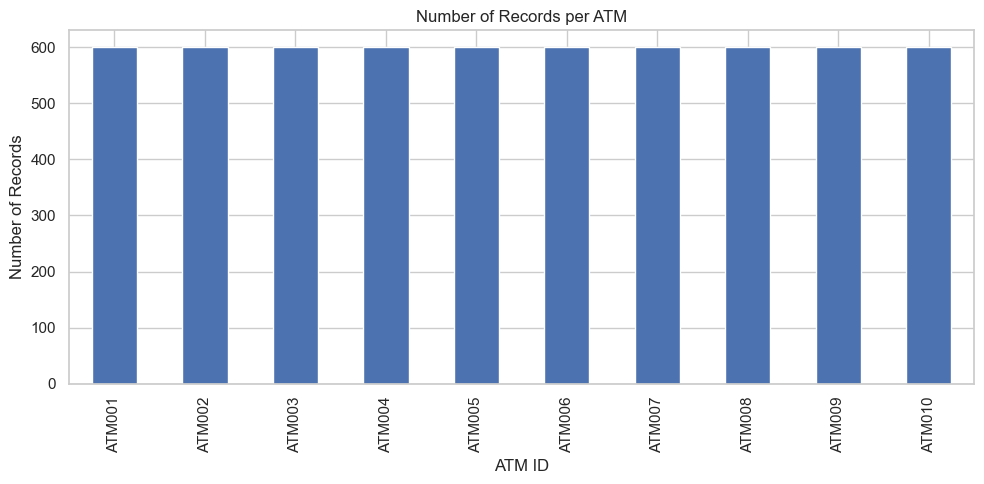

In [11]:
atm_counts = df["ATM_ID"].value_counts().sort_index()

print(atm_counts)

atm_counts.plot(
    kind="bar",
    figsize=(10, 5),
    title="Number of Records per ATM",
    xlabel="ATM ID",
    ylabel="Number of Records"
)

plt.tight_layout()
plt.show()

In [12]:
# Target variable analysis
target = "Cash_Demand_Next_Day"

print("Target statistics:")
print(df[target].describe())

print("\nAverage demand:", df[target].mean())
print("Minimum demand:", df[target].min())
print("Maximum demand:", df[target].max())

Target statistics:
count    6.000000e+03
mean     5.738604e+05
std      1.496854e+05
min      2.192000e+05
25%      4.707750e+05
50%      5.626000e+05
75%      6.655250e+05
max      1.253500e+06
Name: Cash_Demand_Next_Day, dtype: float64

Average demand: 573860.3833333333
Minimum demand: 219200
Maximum demand: 1253500


# Step 5- Cash Demand Distirbution Chart

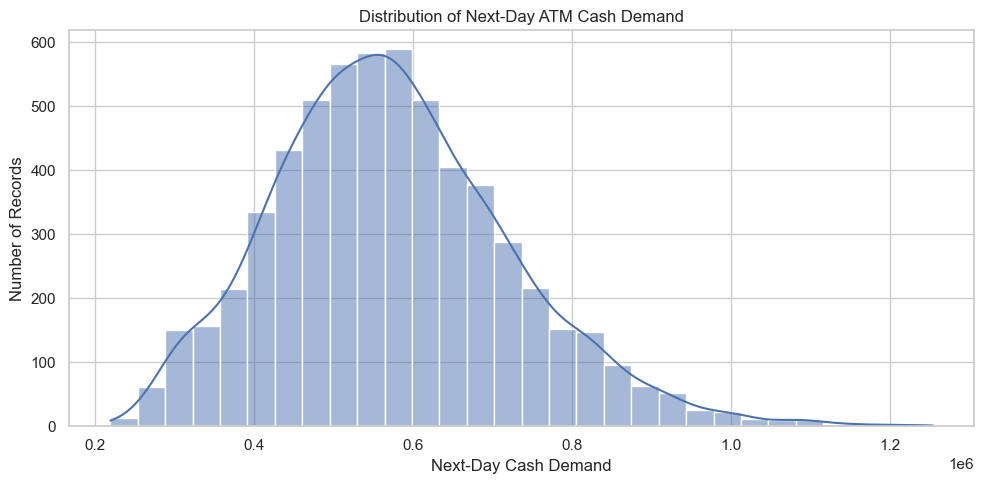

In [13]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Cash_Demand_Next_Day",
    bins=30,
    kde=True
)

plt.title("Distribution of Next-Day ATM Cash Demand")
plt.xlabel("Next-Day Cash Demand")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

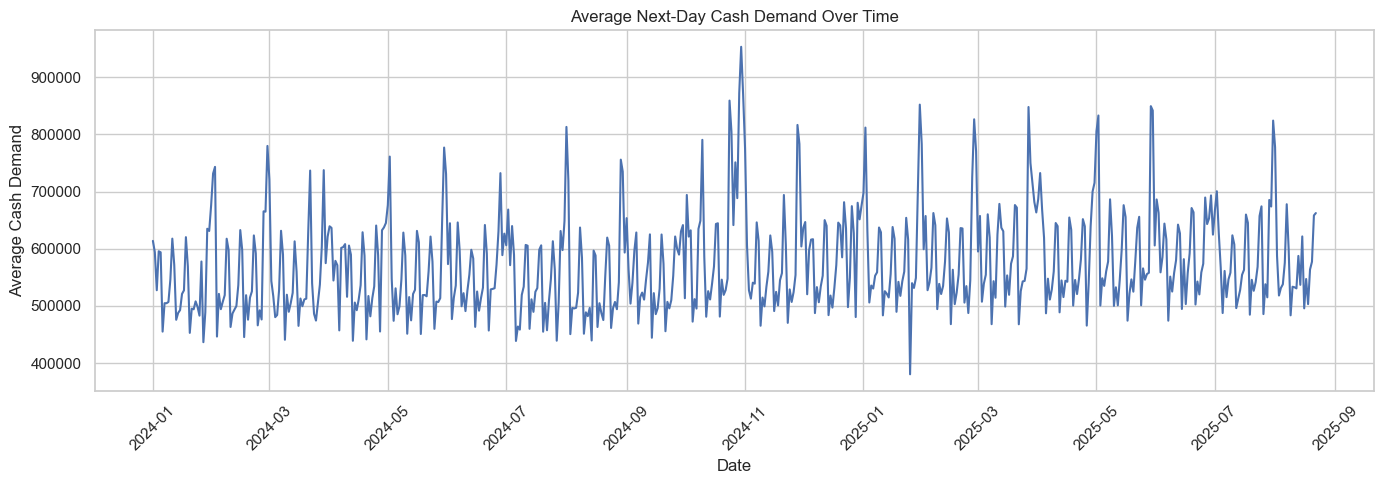

In [14]:
# Date-wise analysis of average cash demand
daily_demand = (
    df.groupby("Date")["Cash_Demand_Next_Day"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(14, 5))

plt.plot(daily_demand.index, daily_demand.values)

plt.title("Average Next-Day Cash Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Average Cash Demand")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

ATM_ID
ATM002    746855.50
ATM005    707062.33
ATM006    649917.83
ATM001    646979.00
ATM003    563717.33
ATM009    551614.67
ATM004    524448.83
ATM008    520774.00
ATM007    476797.00
ATM010    350437.33
Name: Cash_Demand_Next_Day, dtype: float64


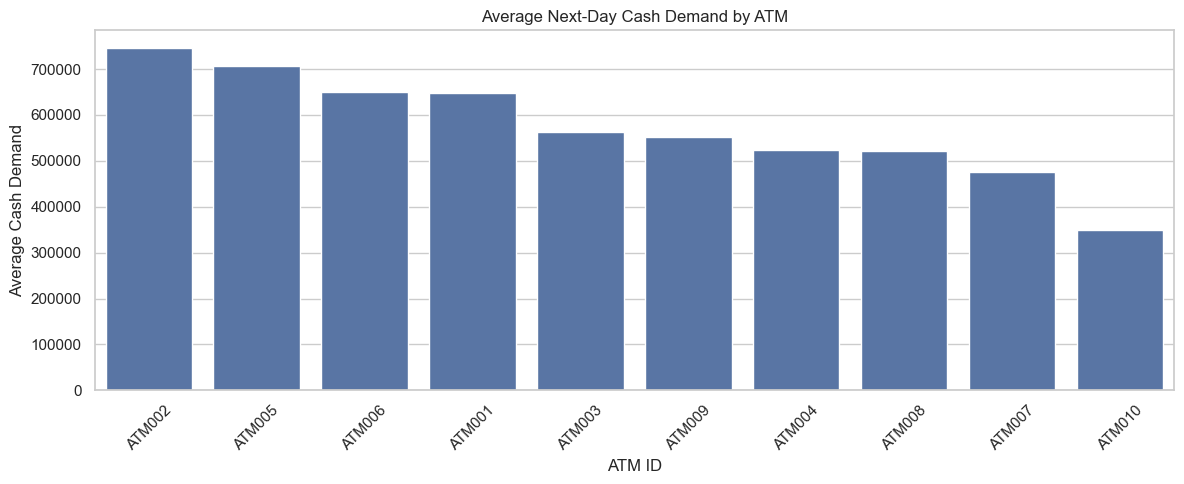

In [15]:
# ATM-wise demand comparison
atm_demand = (
    df.groupby("ATM_ID")["Cash_Demand_Next_Day"]
      .mean()
      .sort_values(ascending=False)
)

print(atm_demand.round(2))

plt.figure(figsize=(12, 5))

sns.barplot(
    x=atm_demand.index,
    y=atm_demand.values
)

plt.title("Average Next-Day Cash Demand by ATM")
plt.xlabel("ATM ID")
plt.ylabel("Average Cash Demand")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Day_of_week
Monday       530718.37
Tuesday      551608.95
Wednesday    579411.05
Thursday     667487.67
Friday       641306.51
Saturday     496251.41
Sunday       549047.76
Name: Cash_Demand_Next_Day, dtype: float64


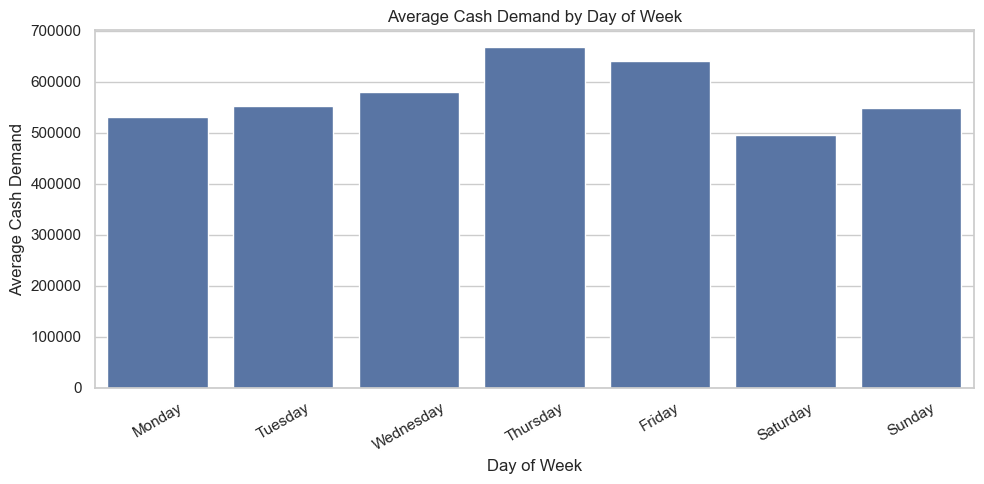

In [16]:
# Weekday-wise analysis of average cash demand
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    df.groupby("Day_of_week")["Cash_Demand_Next_Day"]
      .mean()
      .reindex(weekday_order)
)

print(weekday_demand.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_demand.index,
    y=weekday_demand.values
)

plt.title("Average Cash Demand by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Cash Demand")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

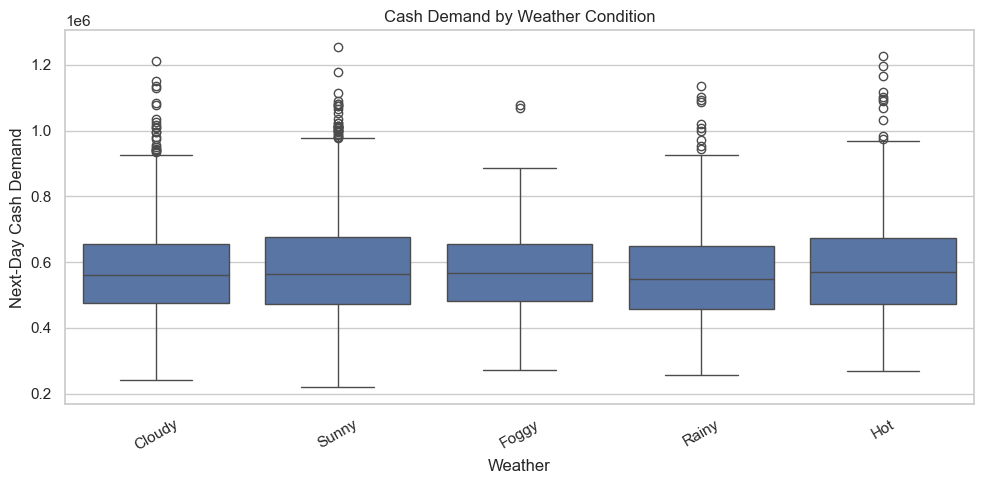

In [17]:
# Weather, holiday, and event analysis
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Weather_Condition",
    y="Cash_Demand_Next_Day"
)

plt.title("Cash Demand by Weather Condition")
plt.xlabel("Weather")
plt.ylabel("Next-Day Cash Demand")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [18]:
print(
    df.groupby("Holiday_Flag")["Cash_Demand_Next_Day"]
      .agg(["count", "mean", "median"])
      .round(2)
)

print(
    df.groupby("Festival_Flag")["Cash_Demand_Next_Day"]
      .agg(["count", "mean", "median"])
      .round(2)
)

              count       mean    median
Holiday_Flag                            
0              5880  573308.55  561650.0
1               120  600900.00  586750.0
               count       mean    median
Festival_Flag                            
0               5700  569291.82  559000.0
1                300  660663.00  634100.0


# Step 6- Numerical correlation analysis

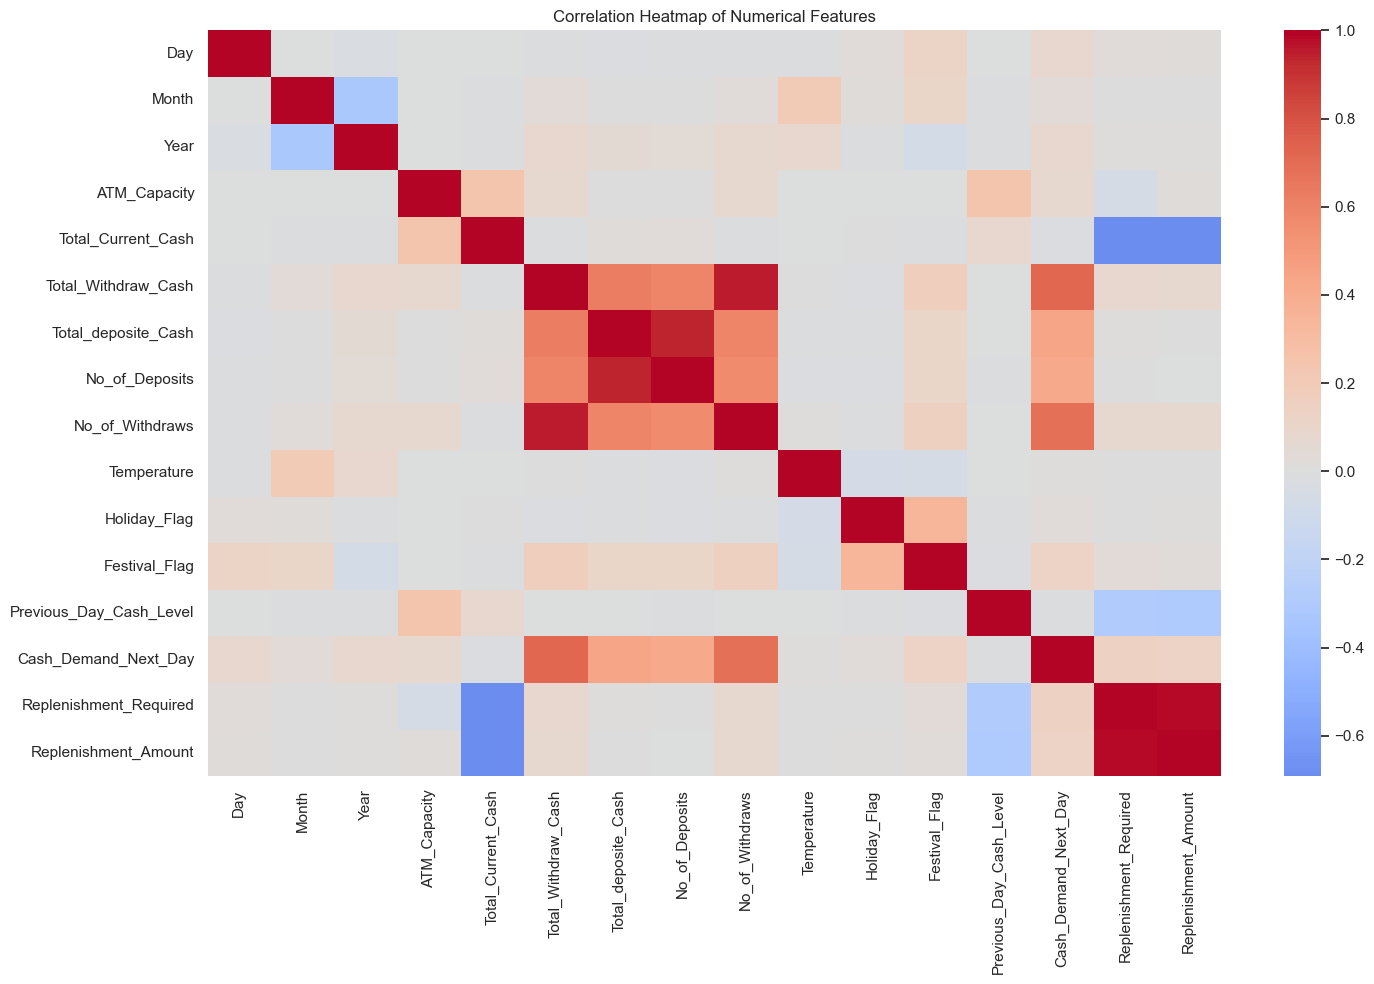

In [19]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(15, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

In [20]:
target_correlation = (
    correlation[target]
    .drop(target)
    .sort_values(ascending=False)
)

print(target_correlation.round(3))

Total_Withdraw_Cash        0.717
No_of_Withdraws            0.679
Total_deposite_Cash        0.440
No_of_Deposits             0.416
Replenishment_Required     0.141
Festival_Flag              0.133
Replenishment_Amount       0.131
Year                       0.086
Day                        0.082
ATM_Capacity               0.080
Month                      0.031
Holiday_Flag               0.026
Temperature                0.012
Previous_Day_Cash_Level   -0.015
Total_Current_Cash        -0.020
Name: Cash_Demand_Next_Day, dtype: float64


# Step 7- Data Consistency and ATM Capacity Check

In [21]:
# Check whether recorded cash values are negative
cash_columns = [
    "ATM_Capacity",
    "Total_Current_Cash",
    "Total_Withdraw_Cash",
    "Total_deposite_Cash",
    "Cash_Demand_Next_Day"
]

print("Negative values in cash columns:")
print((df[cash_columns] < 0).sum())

# Check if current cash exceeds ATM capacity
capacity_issues = df[
    df["Total_Current_Cash"] > df["ATM_Capacity"]
]

print(
    "\nRows where current cash exceeds capacity:",
    len(capacity_issues)
)

# Check demand exceeding capacity
demand_issues = df[
    df["Cash_Demand_Next_Day"] > df["ATM_Capacity"]
]

print(
    "Rows where next-day demand exceeds ATM capacity:",
    len(demand_issues)
)

Negative values in cash columns:
ATM_Capacity            0
Total_Current_Cash      0
Total_Withdraw_Cash     0
Total_deposite_Cash     0
Cash_Demand_Next_Day    0
dtype: int64

Rows where current cash exceeds capacity: 0
Rows where next-day demand exceeds ATM capacity: 0


In [22]:
# Check for potential data leakage
target = "Cash_Demand_Next_Day"

possible_leakage_columns = [
    "Replenishment_Required",
    "Replenishment_Amount"
]

print("Target column:", target)
print("\nColumns requiring leakage review:")

for col in possible_leakage_columns:
    if col in df.columns:
        print("-", col)

Target column: Cash_Demand_Next_Day

Columns requiring leakage review:
- Replenishment_Required
- Replenishment_Amount


# Step 8- Save the Cleaned Dataset

In [23]:
# Work on a copy of the original dataset
clean_df = df.copy()

# Remove completely duplicated rows, if any
clean_df = clean_df.drop_duplicates()

# Remove rows with invalid dates
clean_df = clean_df.dropna(subset=["Date"])

# Sort records by ATM and date
clean_df = clean_df.sort_values(
    ["ATM_ID", "Date"]
).reset_index(drop=True)

# Save the cleaned dataset
clean_df.to_csv(
    "../dataset/ATM_Cash_Demand_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final shape:", clean_df.shape)

Cleaned dataset saved successfully!
Final shape: (6000, 22)


# Step 9- Final Analysis Summary

In [24]:
print("========== DATA ANALYSIS SUMMARY ==========")

print("Total records:", len(clean_df))
print("Total columns:", len(clean_df.columns))
print("Unique ATMs:", clean_df["ATM_ID"].nunique())

print(
    "Date range:",
    clean_df["Date"].min().date(),
    "to",
    clean_df["Date"].max().date()
)

print(
    "Missing values:",
    clean_df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    clean_df.duplicated().sum()
)

print(
    "Average next-day demand:",
    round(clean_df["Cash_Demand_Next_Day"].mean(), 2)
)

print("============================================")

========== DATA ANALYSIS SUMMARY ==========
Total records: 6000
Total columns: 22
Unique ATMs: 10
Date range: 2024-01-01 to 2025-08-22
Missing values: 0
Duplicate rows: 0
Average next-day demand: 573860.38
